# Final-hub ranking

In [1]:
import copy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from matplotlib.ticker import MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
extra = 3
plt.rcParams.update({
    "font.size": 14+extra,
    "axes.titlesize": 17+extra,
    "axes.labelsize": 15+extra,
    "xtick.labelsize": 12+extra,
    "ytick.labelsize": 12+extra,
    "legend.fontsize": 12+extra,
    "legend.title_fontsize": 13+extra,
    "figure.titlesize": 19+extra,
})

project_root = next(
    (
        path
        for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (path / "pyproject.toml").is_file() and (path / "tasks").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Run this notebook from the network-creation repository.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from network_creation.core.model import ActorScheduler
from network_creation.io import read_json
from network_creation.observers.hub_ranking_observer import (
    HubRankingObserver,
    HubRankingResult,
)
from network_creation.stats.hub_ranking import (
    simultaneous_cmc_band,
    tie_aware_hit_at_k,
)
from tasks.policies import (
    load_policy_results,
    prepare_instrumented_policy_simulation,
)

## Configuration

In [2]:
CONFIG = {
    "source_zarr": (
        project_root
        / "artifacts"
        / "simulation_runs"
        / "run-20260809T034029.zarr"
    ),
    "objective": "centered_mean_welfare.mean",
    "ranking": {
        "group_sizes": [10, 50, 100],
        "seed": 13,
        "n_episodes": 2**9,
        "n_batches": 20,
        "n_jobs": 5,
        "bootstrap_seed": 13,
        "bootstrap_resamples": 4000,
        "test_seed": 13,
        "test_resamples": 9999,
        "familywise_alpha": 0.05,
    },
}

## Select the final-welfare argmax for each network size

In [3]:
def load_highest_welfare_inputs(config, group_sizes):
    """Load the source once and return its config and maximizing input indices."""

    result_store = Path(config["source_zarr"])
    objective = str(config["objective"])
    run_config = read_json(result_store / "run_config.json")
    results = load_policy_results(
        result_store, stats=(objective,), normalize_time=False
    )
    input_indices = {}
    for raw_group_size in group_sizes:
        group_size = int(raw_group_size)
        final_step = int(
            results.coords["last_valid_raw_step"].sel(n_agents=group_size).item()
        )
        scores = results["x"].sel(
            n_agents=group_size, observable=objective, step=final_step, drop=True
        )
        values = np.asarray(scores.values, dtype=float)
        best_welfare = float(np.nanmax(values))
        positions = np.argwhere(np.isfinite(values) & (values == best_welfare))
        candidate_indices = []
        for position in positions:
            selector = {
                dimension: scores.coords[dimension].values[int(index)].item()
                for dimension, index in zip(scores.dims, position, strict=True)
            }
            input_index = results.coords["input_index"].sel(
                {"n_agents": group_size, **selector}
            ).item()
            candidate_indices.append(int(input_index))
        input_indices[group_size] = min(candidate_indices)
    return run_config, input_indices

In [4]:
figure_output_dir = (
    project_root / "artifacts" / "figures" / Path(CONFIG["source_zarr"]).stem
)
figure_output_dir.mkdir(parents=True, exist_ok=True)

## Rank distribution of the final-network hub

In [5]:
def simulate_hub_ranking_batch(simulation_template, n_episodes, simulation_seed):
    """Simulate one episode batch and return its ranking observations."""

    prepared = copy.deepcopy(simulation_template)
    simulator = prepared.simulator
    observer = simulator.observers[0]
    simulator.rng = np.random.default_rng(simulation_seed)
    simulator.actor_scheduler = ActorScheduler(
        seed=simulation_seed,
        n_agents=prepared.settings.n_agents,
        n_actors=prepared.settings.n_actors,
        activation_weights=tuple(
            agent.activation_weight for agent in simulator.agents
        ),
    )
    simulator.run(n_episodes=n_episodes, reset_observers=True)
    return observer.get()


def simulate_hub_ranking_for_group_size(
    parallel_executor, simulation_template, group_size, ranking_options, seed
):
    """Simulate all ranking episodes for one network size in parallel batches."""

    n_episodes = int(ranking_options["n_episodes"])
    if n_episodes < 1:
        raise ValueError("n_episodes must be positive")
    requested_batches = int(ranking_options["n_batches"])
    if requested_batches < 1:
        raise ValueError("n_batches must be positive")
    n_batches = min(n_episodes, requested_batches)
    base_size, remainder = divmod(n_episodes, n_batches)
    batch_sizes = [
        base_size + (batch_index < remainder)
        for batch_index in range(n_batches)
    ]
    seed_sequences = np.random.SeedSequence(seed).spawn(len(batch_sizes))
    batch_seeds = [
        int(sequence.generate_state(1, dtype=np.uint64)[0])
        for sequence in seed_sequences
    ]
    jobs = (
        delayed(simulate_hub_ranking_batch)(
            simulation_template,
            batch_size,
            batch_seed,
        )
        for batch_size, batch_seed in zip(batch_sizes, batch_seeds, strict=True)
    )
    batch_results = list(
        tqdm(
            parallel_executor(jobs),
            total=len(batch_sizes),
            desc=f"Ranking (n={group_size})",
            unit="batch",
        )
    )
    return HubRankingResult(
        actor_order=np.concatenate(
            [result.actor_order for result in batch_results]
        ),
        recipient_order=np.concatenate(
            [result.recipient_order for result in batch_results]
        ),
        final_hub_id=np.concatenate(
            [result.final_hub_id for result in batch_results]
        ),
    )


def retain_unique_hub_episodes(ranking_result):
    """Keep episodes whose terminal network has one highest-degree node."""

    unique_hub = ranking_result.final_hub_id >= 0
    return HubRankingResult(
        actor_order=ranking_result.actor_order[unique_hub],
        recipient_order=ranking_result.recipient_order[unique_hub],
        final_hub_id=ranking_result.final_hub_id[unique_hub],
    )


def simulate_unique_hub_episodes_by_group_size(
    parallel_executor, run_config, input_indices, ranking_options
):
    """Simulate and retain unique-hub episodes for each network size."""

    episodes_by_group_size = {}
    for group_index, raw_group_size in enumerate(ranking_options["group_sizes"]):
        group_size = int(raw_group_size)
        seed = int(ranking_options["seed"]) + group_index
        simulation_config = copy.deepcopy(run_config)
        simulation_config["simulator"]["seed"] = seed
        simulation_config["simulator"]["n_episodes"] = int(
            ranking_options["n_episodes"]
        )
        observer = HubRankingObserver(n_agents=group_size)
        simulation_template = prepare_instrumented_policy_simulation(
            simulation_config,
            input_index=input_indices[group_size],
            observers=(observer,),
        )
        ranking_result = simulate_hub_ranking_for_group_size(
            parallel_executor,
            simulation_template,
            group_size,
            ranking_options,
            seed,
        )
        episodes_by_group_size[group_size] = retain_unique_hub_episodes(
            ranking_result
        )
    return episodes_by_group_size


def compute_expected_hub_ranks(order, hub_ids):
    """Return final-hub ranks with random ordering inside bottom ties."""

    hit_at_k = tie_aware_hit_at_k(order, hub_ids)
    return order.shape[1] - hit_at_k[:, :-1].sum(axis=1)


def compute_adjusted_hub_rank_tests(episodes_by_group_size, ranking_options):
    """Return rank-test rows with Holm-adjusted p-values and conclusions."""

    test_rows = []
    for group_index, (group_size, episodes) in enumerate(
        episodes_by_group_size.items()
    ):
        hub_ids = episodes.final_hub_id
        actor_ranks = compute_expected_hub_ranks(episodes.actor_order, hub_ids)
        recipient_ranks = compute_expected_hub_ranks(
            episodes.recipient_order, hub_ids
        )
        paired_difference = np.round(actor_ranks - recipient_ranks, decimals=12)
        paired_result = stats.wilcoxon(
            paired_difference,
            zero_method="pratt",
            alternative="two-sided",
            method=stats.PermutationMethod(
                n_resamples=int(ranking_options["test_resamples"]),
                rng=np.random.default_rng(
                    int(ranking_options["test_seed"]) + group_index
                ),
            ),
        )
        test_rows.append({
            "n_agents": int(group_size),
            "comparison": "First to act - first to receive",
            "test": "Paired Wilcoxon",
            "episodes": len(hub_ids),
            "mean_difference": float(paired_difference.mean()),
            "median_difference": float(np.median(paired_difference)),
            "statistic": float(paired_result.statistic),
            "pvalue": float(paired_result.pvalue),
            "negative_conclusion": "First to act ranks earlier",
            "positive_conclusion": "First to receive ranks earlier",
        })

        chance_rank = (group_size + 1.0) / 2.0
        for comparison, ranks in (
            ("First to act - chance", actor_ranks),
            ("First to receive - chance", recipient_ranks),
        ):
            difference = ranks - chance_rank
            if np.all(difference == 0.0):
                statistic, pvalue = 0.0, 1.0
            else:
                test_result = stats.ttest_1samp(
                    ranks, popmean=chance_rank, alternative="two-sided"
                )
                statistic = float(test_result.statistic)
                pvalue = float(test_result.pvalue)
            test_rows.append({
                "n_agents": int(group_size),
                "comparison": comparison,
                "test": "One-sample t",
                "episodes": len(hub_ids),
                "mean_difference": float(difference.mean()),
                "median_difference": float(np.median(difference)),
                "statistic": statistic,
                "pvalue": pvalue,
                "negative_conclusion": "Better than chance",
                "positive_conclusion": "Worse than chance",
            })

    pvalues = np.asarray([row["pvalue"] for row in test_rows], dtype=float)
    familywise_alpha = float(ranking_options["familywise_alpha"])
    rejected, holm_pvalues, _, _ = multipletests(
        pvalues, alpha=familywise_alpha, method="holm"
    )
    for row, is_rejected, holm_pvalue in zip(
        test_rows, rejected, holm_pvalues, strict=True
    ):
        row["holm_pvalue"] = float(holm_pvalue)
        if not is_rejected:
            row["conclusion"] = "No detected effect"
        elif row["mean_difference"] < 0.0:
            row["conclusion"] = row["negative_conclusion"]
        elif row["mean_difference"] > 0.0:
            row["conclusion"] = row["positive_conclusion"]
        else:
            row["conclusion"] = "Effect detected without a net direction"
    return test_rows


def format_pvalue_for_table(value):
    """Format one p-value for the Markdown results table."""

    return "<0.0001" if value < 1e-4 else f"{value:.4f}"


def format_hub_rank_test_table(test_rows, *, familywise_alpha):
    """Build the Markdown table from hub-rank test rows."""

    table = [
        "### Rank comparison tests",
        "",
        (
            "Lower rank is better. Pair differences are first-to-act minus "
            "first-to-receive; chance differences are observed minus $(n+1)/2$."
        ),
        "",
        (
            "| $n$ | Comparison | Test | Episodes | Mean rank diff. | "
            "Median rank diff. | Statistic | $p$ | Holm $p$ | Conclusion |"
        ),
        "|---:|:---|:---|---:|---:|---:|---:|---:|---:|:---|",
    ]
    for row in test_rows:
        table.append(
            f"| {row['n_agents']} | {row['comparison']} | {row['test']} | "
            f"{row['episodes']} | {row['mean_difference']:+.3f} | "
            f"{row['median_difference']:+.3f} | {row['statistic']:.3f} | "
            f"{format_pvalue_for_table(row['pvalue'])} | "
            f"{format_pvalue_for_table(row['holm_pvalue'])} | "
            f"{row['conclusion']} |"
        )
    table.extend((
        "",
        (
            "Paired Wilcoxon p-values use permutation calibration for ties. "
            "Chance comparisons use two-sided one-sample t-tests. Holm "
            f"correction covers all displayed tests at family-wise "
            f"alpha={familywise_alpha:g}."
        ),
    ))
    return "\n".join(table)


def plot_cumulative_hub_rank_distributions(
    episodes_by_group_size, ranking_options
):
    """Plot tie-aware cumulative hub ranks and simultaneous confidence bands."""

    names = ("First to act", "First to receive a link")
    colors = ("#1f4e79", "#d97706")
    figure, axes = plt.subplots(
        1, len(episodes_by_group_size), figsize=(15.5, 6.5),
        sharey=True, layout="constrained",
    )
    axes = np.atleast_1d(axes)
    #figure.suptitle("Rank distribution of the final-network hub")
    for column, (group_size, episodes) in enumerate(
        episodes_by_group_size.items()
    ):
        hub_ids = episodes.final_hub_id
        scores = np.stack(
            (
                tie_aware_hit_at_k(episodes.actor_order, hub_ids),
                tie_aware_hit_at_k(episodes.recipient_order, hub_ids),
            ),
            axis=1,
        )
        band = simultaneous_cmc_band(
            scores,
            n_resamples=int(ranking_options["bootstrap_resamples"]),
            seed=int(ranking_options["bootstrap_seed"]) + column,
        )
        ranks = np.arange(1, group_size + 1)
        chance = ranks / group_size
        axis = axes[column]
        for index, (name, color) in enumerate(zip(names, colors, strict=True)):
            axis.fill_between(
                ranks, band.low[index], band.high[index],
                color=color, alpha=0.16,
            )
            axis.plot(
                ranks, band.observed[index], color=color, linewidth=2.2,
                label=name,
            )
        axis.plot(
            ranks, chance, color="#555555", linestyle="--", linewidth=1.6,
            label="Chance level",
        )
        ticks = np.linspace(0.0, 1.0, 6)
        axis.set_yticks(ticks, [rf"{100 * tick:.0f}\%" for tick in ticks])
        axis.set(
            xlim=(1, group_size), ylim=(0.0, 1.0),
            xlabel=r"Rank threshold, $k$",
            title=rf"($n = {group_size}$)",
        )
        axis.set_box_aspect(1)
        x_ticks = MaxNLocator(integer=True, nbins=6).tick_values(1, group_size)
        x_ticks = x_ticks[(1 <= x_ticks) & (x_ticks <= group_size)]
        axis.set_xticks(np.unique(np.concatenate(([1.0], x_ticks))))
        axis.minorticks_off()
        axis.grid(alpha=0.25)
        if column == 0:
            axis.set_ylabel(
                r"Cumulative probability, $\Pr(R_{\mathrm{hub}} \leq k)$"
            )
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(
        handles, labels, loc="outside lower center", ncols=len(labels)
    )
    return figure

Ranking (n=10):   0%|          | 0/20 [00:00<?, ?batch/s]

Ranking (n=10):   5%|▌         | 1/20 [00:02<00:56,  2.97s/batch]

Ranking (n=10):  30%|███       | 6/20 [00:03<00:06,  2.16batch/s]

Ranking (n=10):  35%|███▌      | 7/20 [00:04<00:08,  1.52batch/s]

Ranking (n=10):  45%|████▌     | 9/20 [00:05<00:04,  2.27batch/s]

...

Ranking (n=100):  85%|████████▌ | 17/20 [03:28<00:36, 12.09s/batch]

Ranking (n=100):  90%|█████████ | 18/20 [03:28<00:18,  9.26s/batch]

Ranking (n=100):  95%|█████████▌| 19/20 [03:29<00:07,  7.15s/batch]

Ranking (n=100): 100%|██████████| 20/20 [03:30<00:00,  5.52s/batch]

Ranking (n=100): 100%|██████████| 20/20 [03:30<00:00, 10.54s/batch]

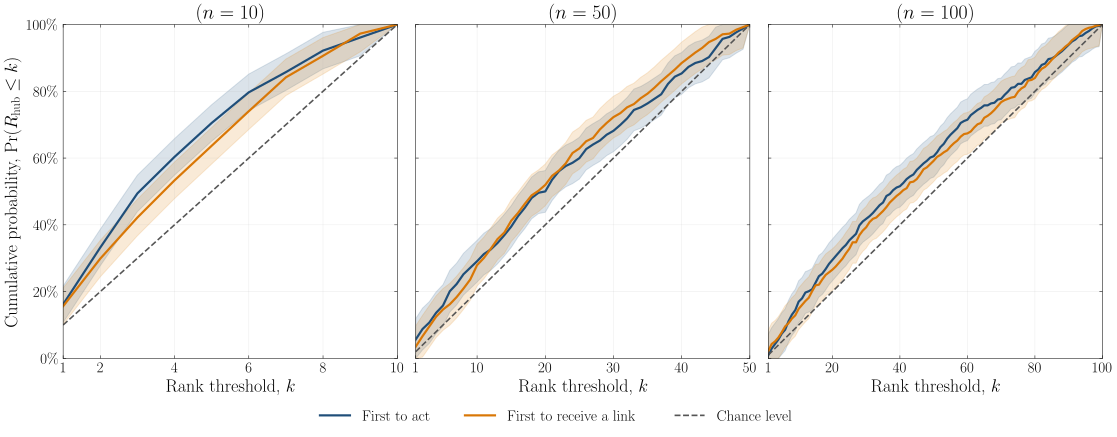

In [6]:
ranking_options = CONFIG["ranking"]
run_config, input_indices = load_highest_welfare_inputs(
    CONFIG, ranking_options["group_sizes"]
)
with Parallel(
    n_jobs=int(ranking_options["n_jobs"]),
    backend="loky",
    return_as="generator",
    batch_size=1,
) as parallel_executor:
    unique_hub_episodes = simulate_unique_hub_episodes_by_group_size(
        parallel_executor, run_config, input_indices, ranking_options
    )

rank_test_rows = compute_adjusted_hub_rank_tests(
    unique_hub_episodes, ranking_options
)
hub_rank_figure = plot_cumulative_hub_rank_distributions(
    unique_hub_episodes, ranking_options
)
hub_rank_figure_path = figure_output_dir / "final_hub_cmc_by_group_size.pdf"
hub_rank_figure.savefig(
    hub_rank_figure_path, format="pdf", bbox_inches="tight"
)
display(hub_rank_figure)
plt.close(hub_rank_figure)

In [7]:
display(Markdown(format_hub_rank_test_table(
    rank_test_rows,
    familywise_alpha=float(ranking_options["familywise_alpha"]),
)))

### Rank comparison tests

Lower rank is better. Pair differences are first-to-act minus first-to-receive; chance differences are observed minus $(n+1)/2$.

| $n$ | Comparison | Test | Episodes | Mean rank diff. | Median rank diff. | Statistic | $p$ | Holm $p$ | Conclusion |
|---:|:---|:---|---:|---:|---:|---:|---:|---:|:---|
| 10 | First to act - first to receive | Paired Wilcoxon | 512 | -0.326 | +0.000 | 59101.500 | 0.0576 | 0.1728 | No detected effect |
| 10 | First to act - chance | One-sample t | 512 | -1.334 | -1.500 | -11.649 | <0.0001 | <0.0001 | Better than chance |
| 10 | First to receive - chance | One-sample t | 512 | -1.008 | -1.500 | -8.632 | <0.0001 | <0.0001 | Better than chance |
| 50 | First to act - first to receive | Paired Wilcoxon | 512 | +0.566 | +1.000 | 63364.500 | 0.4922 | 0.8564 | No detected effect |
| 50 | First to act - chance | One-sample t | 512 | -3.646 | -5.000 | -5.620 | <0.0001 | <0.0001 | Better than chance |
| 50 | First to receive - chance | One-sample t | 512 | -4.213 | -6.500 | -6.946 | <0.0001 | <0.0001 | Better than chance |
| 100 | First to act - first to receive | Paired Wilcoxon | 512 | -1.736 | -1.000 | 63089.500 | 0.4282 | 0.8564 | No detected effect |
| 100 | First to act - chance | One-sample t | 512 | -8.049 | -12.500 | -6.370 | <0.0001 | <0.0001 | Better than chance |
| 100 | First to receive - chance | One-sample t | 512 | -6.312 | -9.500 | -4.966 | <0.0001 | <0.0001 | Better than chance |

Paired Wilcoxon p-values use permutation calibration for ties. Chance comparisons use two-sided one-sample t-tests. Holm correction covers all displayed tests at family-wise alpha=0.05.

In [8]:
table = [
    "### Final hub in the first half of the ordering",
    "",
    "Entries are cumulative probabilities at $k=n/2$ with 95% simultaneous bootstrap bands.",
    "",
    "| Network size | First to act | First to receive a link | Chance |",
    "|---:|---:|---:|---:|",
]
for column, (group_size, episodes) in enumerate(unique_hub_episodes.items()):
    hub_ids = episodes.final_hub_id
    scores = np.stack((
        tie_aware_hit_at_k(episodes.actor_order, hub_ids),
        tie_aware_hit_at_k(episodes.recipient_order, hub_ids),
    ), axis=1)
    band = simultaneous_cmc_band(
        scores,
        n_resamples=int(ranking_options["bootstrap_resamples"]),
        seed=int(ranking_options["bootstrap_seed"]) + column,
    )
    threshold = group_size // 2
    intervals = [
        f"{estimate:.1%} [{low:.1%}, {high:.1%}]"
        for estimate, low, high in zip(
            band.observed[:, threshold - 1],
            band.low[:, threshold - 1],
            band.high[:, threshold - 1],
            strict=True,
        )
    ]
    table.append(
        f"| {group_size} | {intervals[0]} | {intervals[1]} | "
        f"{threshold / group_size:.0%} |"
    )
display(Markdown("\n".join(table)))

### Final hub in the first half of the ordering

Entries are cumulative probabilities at $k=n/2$ with 95% simultaneous bootstrap bands.

| Network size | First to act | First to receive a link | Chance |
|---:|---:|---:|---:|
| 10 | 70.5% [65.0%, 76.0%] | 63.7% [58.2%, 69.1%] | 50% |
| 50 | 60.0% [53.7%, 66.2%] | 62.9% [56.6%, 69.1%] | 50% |
| 100 | 60.5% [54.3%, 66.8%] | 59.2% [52.9%, 65.4%] | 50% |

## Bayesian rank and first-half comparisons

Each Bayesian-bootstrap draw assigns one Dirichlet weight to each retained unique-hub episode. Reusing that weight for actor and recipient outcomes preserves pairing. Positive rank advantage means the named ordering places the final hub earlier. The first-half analysis retains 50% as a visual chance reference rather than repeating separate chance contrasts. Posterior areas are reported directly, with no ROPE or multiplicity correction.

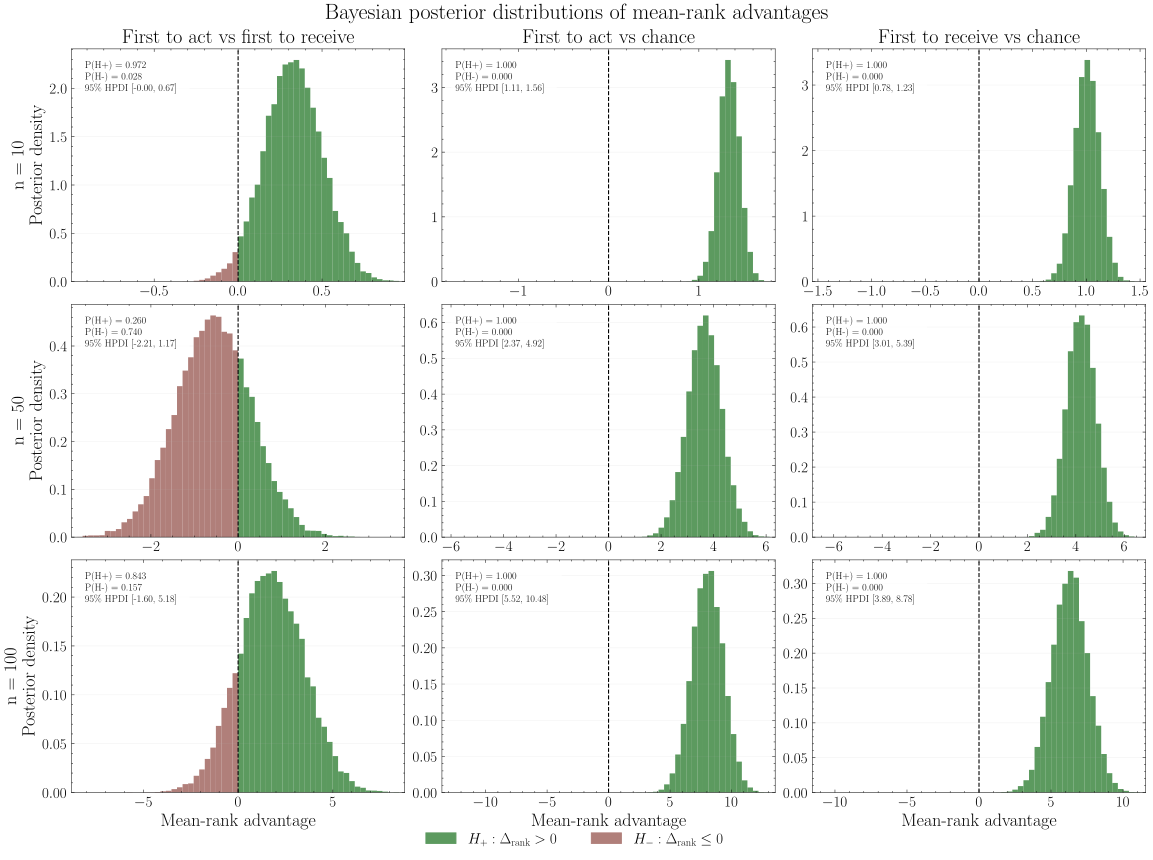

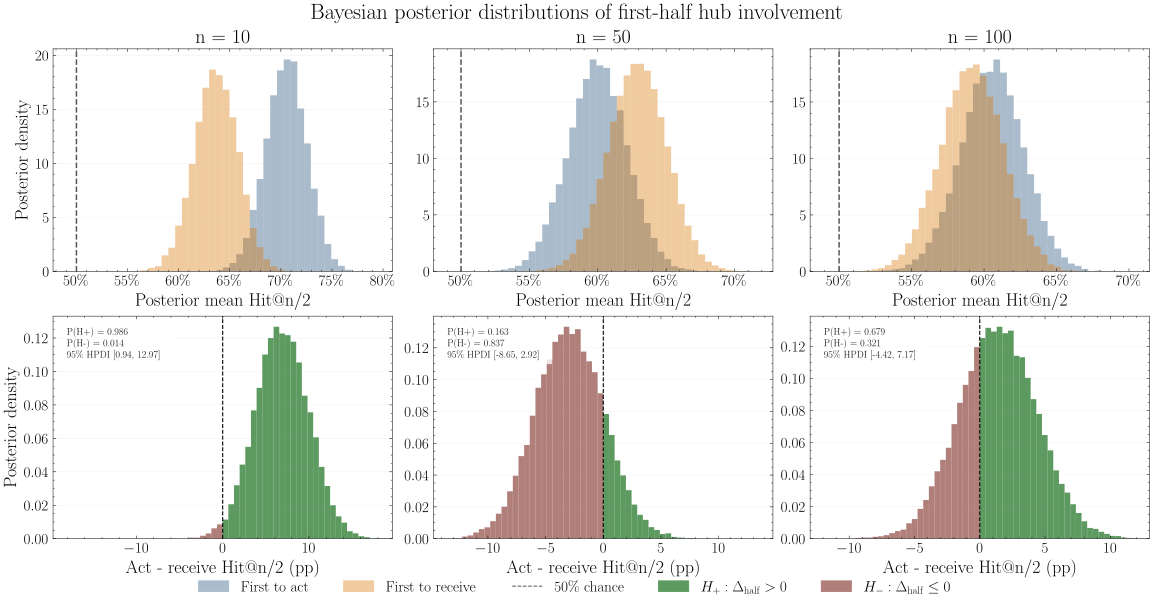

Saved Bayesian rank figure: /home/hdahmou/Projects/Network_creation/artifacts/figures/run-20260809T034029/final_hub_bayesian_rank_advantages.pdf
Saved Bayesian first-half figure: /home/hdahmou/Projects/Network_creation/artifacts/figures/run-20260809T034029/final_hub_bayesian_first_half.pdf


In [9]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import jax.numpy as jnp
from jax import config as jax_config, random
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpyro.distributions as dist
from numpyro.diagnostics import hpdi

jax_config.update("jax_enable_x64", True)

BAYESIAN_BOOTSTRAP_DRAWS = 20_000
BAYESIAN_BOOTSTRAP_CREDIBLE_MASS = 0.95
BAYESIAN_BOOTSTRAP_SEED = int(ranking_options["test_seed"])


def posterior_hpdi(draws):
    return np.asarray(hpdi(
        jnp.asarray(draws), prob=BAYESIAN_BOOTSTRAP_CREDIBLE_MASS
    ))


rank_comparisons = (
    "First to act vs first to receive",
    "First to act vs chance",
    "First to receive vs chance",
)
group_sizes = tuple(unique_hub_episodes)
bootstrap_keys = random.split(
    random.key(BAYESIAN_BOOTSTRAP_SEED), len(group_sizes)
)
rank_effects_by_size = {}
first_half_rates_by_size = {}
first_half_effects_by_size = {}
first_half_chance_by_size = {}

for bootstrap_key, (group_size, episodes) in zip(
    bootstrap_keys, unique_hub_episodes.items(), strict=True
):
    hub_ids = episodes.final_hub_id
    actor_ranks = compute_expected_hub_ranks(episodes.actor_order, hub_ids)
    recipient_ranks = compute_expected_hub_ranks(
        episodes.recipient_order, hub_ids
    )
    threshold = group_size // 2
    actor_hit_at_half = tie_aware_hit_at_k(
        episodes.actor_order, hub_ids
    )[:, threshold - 1]
    recipient_hit_at_half = tie_aware_hit_at_k(
        episodes.recipient_order, hub_ids
    )[:, threshold - 1]
    episode_values = jnp.asarray(np.column_stack((
        actor_ranks,
        recipient_ranks,
        actor_hit_at_half,
        recipient_hit_at_half,
    )))
    weights = dist.Dirichlet(
        jnp.ones(len(hub_ids), dtype=jnp.float64)
    ).sample(
        bootstrap_key, sample_shape=(BAYESIAN_BOOTSTRAP_DRAWS,)
    )
    posterior_means = np.asarray(weights @ episode_values)
    chance_rank = (group_size + 1.0) / 2.0
    rank_effects_by_size[group_size] = {
        rank_comparisons[0]: posterior_means[:, 1] - posterior_means[:, 0],
        rank_comparisons[1]: chance_rank - posterior_means[:, 0],
        rank_comparisons[2]: chance_rank - posterior_means[:, 1],
    }
    first_half_rates_by_size[group_size] = {
        "First to act": posterior_means[:, 2],
        "First to receive": posterior_means[:, 3],
    }
    first_half_effects_by_size[group_size] = (
        posterior_means[:, 2] - posterior_means[:, 3]
    )
    first_half_chance_by_size[group_size] = threshold / group_size

display(Markdown(
    "## Bayesian rank and first-half comparisons\n\n"
    "Each Bayesian-bootstrap draw assigns one Dirichlet weight to each "
    "retained unique-hub episode. Reusing that weight for actor and "
    "recipient outcomes preserves pairing. Positive rank advantage means "
    "the named ordering places the final hub earlier. The first-half "
    "analysis retains 50% as a visual chance reference rather than "
    "repeating separate chance contrasts. Posterior areas are reported "
    "directly, with no ROPE or multiplicity correction."
))

positive_color = "#2e7d32"
negative_color = "#9a5b55"


def plot_signed_posterior(axis, draws, *, scale, xlabel):
    values = scale * np.asarray(draws)
    maximum_absolute = max(float(np.max(np.abs(values))), np.finfo(float).eps)
    limit = 1.05 * maximum_absolute
    bin_edges = np.linspace(-limit, limit, 61)
    density, bin_edges = np.histogram(values, bins=bin_edges, density=True)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    axis.bar(
        bin_centers,
        density,
        width=np.diff(bin_edges),
        color=np.where(bin_centers > 0.0, positive_color, negative_color),
        alpha=0.78,
        linewidth=0,
    )
    lower, upper = posterior_hpdi(values)
    probability_h_plus = np.mean(values > 0.0)
    probability_h_minus = np.mean(values <= 0.0)
    np.testing.assert_allclose(probability_h_plus + probability_h_minus, 1.0)
    axis.axvline(0.0, color="black", linestyle="--", linewidth=1.1)
    axis.text(
        0.04,
        0.95,
        f"P(H+) = {probability_h_plus:.3f}\n"
        f"P(H-) = {probability_h_minus:.3f}\n"
        rf"95\% HPDI [{lower:.2f}, {upper:.2f}]",
        transform=axis.transAxes,
        va="top",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78},
    )
    axis.set(xlim=(-limit, limit), xlabel=xlabel)
    axis.grid(axis="y", alpha=0.18)


rank_figure, rank_axes = plt.subplots(
    len(group_sizes), len(rank_comparisons),
    figsize=(16.0, 12.0), layout="constrained",
)
for row, group_size in enumerate(group_sizes):
    for column, comparison in enumerate(rank_comparisons):
        axis = rank_axes[row, column]
        plot_signed_posterior(
            axis,
            rank_effects_by_size[group_size][comparison],
            scale=1.0,
            xlabel="Mean-rank advantage" if row == len(group_sizes) - 1 else "",
        )
        if row == 0:
            axis.set_title(comparison)
        if column == 0:
            axis.set_ylabel(f"n = {group_size}\nPosterior density")
rank_figure.suptitle("Bayesian posterior distributions of mean-rank advantages")
rank_figure.legend(
    handles=[
        Patch(
            color=positive_color, alpha=0.78,
            label=r"$H_+: \Delta_{\mathrm{rank}} > 0$",
        ),
        Patch(
            color=negative_color, alpha=0.78,
            label=r"$H_-: \Delta_{\mathrm{rank}} \leq 0$",
        ),
    ],
    loc="outside lower center",
    ncols=2,
    frameon=False,
)
rank_figure_path = figure_output_dir / "final_hub_bayesian_rank_advantages.pdf"
rank_figure.savefig(rank_figure_path, format="pdf", bbox_inches="tight")
display(rank_figure)
plt.close(rank_figure)

actor_color = "#1f4e79"
recipient_color = "#d97706"
first_half_figure, first_half_axes = plt.subplots(
    2, len(group_sizes), figsize=(16.0, 8.5), layout="constrained"
)
for column, group_size in enumerate(group_sizes):
    actor_draws = first_half_rates_by_size[group_size]["First to act"]
    recipient_draws = first_half_rates_by_size[group_size]["First to receive"]
    chance = first_half_chance_by_size[group_size]
    minimum = min(float(actor_draws.min()), float(recipient_draws.min()), chance)
    maximum = max(float(actor_draws.max()), float(recipient_draws.max()), chance)
    padding = max(0.02, 0.08 * (maximum - minimum))
    distribution_edges = np.linspace(
        max(0.0, minimum - padding), min(1.0, maximum + padding), 51
    )
    rate_axis = first_half_axes[0, column]
    rate_axis.hist(
        actor_draws, bins=distribution_edges, density=True,
        color=actor_color, alpha=0.38, linewidth=0,
    )
    rate_axis.hist(
        recipient_draws, bins=distribution_edges, density=True,
        color=recipient_color, alpha=0.38, linewidth=0,
    )
    rate_axis.axvline(
        chance, color="#555555", linestyle="--", linewidth=1.5
    )
    rate_axis.set(
        xlim=(distribution_edges[0], distribution_edges[-1]),
        title=f"n = {group_size}",
        xlabel="Posterior mean Hit@n/2",
    )
    rate_axis.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    rate_axis.grid(axis="y", alpha=0.18)
    if column == 0:
        rate_axis.set_ylabel("Posterior density")

    difference_axis = first_half_axes[1, column]
    plot_signed_posterior(
        difference_axis,
        first_half_effects_by_size[group_size],
        scale=100.0,
        xlabel="Act - receive Hit@n/2 (pp)",
    )
    if column == 0:
        difference_axis.set_ylabel("Posterior density")
first_half_figure.suptitle(
    "Bayesian posterior distributions of first-half hub involvement"
)
first_half_figure.legend(
    handles=[
        Patch(color=actor_color, alpha=0.38, label="First to act"),
        Patch(color=recipient_color, alpha=0.38, label="First to receive"),
        Line2D(
            [0], [0], color="#555555", linestyle="--",
            label=r"50\% chance",
        ),
        Patch(
            color=positive_color, alpha=0.78,
            label=r"$H_+: \Delta_{\mathrm{half}} > 0$",
        ),
        Patch(
            color=negative_color, alpha=0.78,
            label=r"$H_-: \Delta_{\mathrm{half}} \leq 0$",
        ),
    ],
    loc="outside lower center",
    ncols=5,
    frameon=False,
)
first_half_figure_path = (
    figure_output_dir / "final_hub_bayesian_first_half.pdf"
)
first_half_figure.savefig(
    first_half_figure_path, format="pdf", bbox_inches="tight"
)
display(first_half_figure)
plt.close(first_half_figure)
print(f"Saved Bayesian rank figure: {rank_figure_path}")
print(f"Saved Bayesian first-half figure: {first_half_figure_path}")